Objectif : prévoir la variance du lendemain (h = 1) avec GARCH(1,1), GJR-GARCH et EGARCH en loi de Student, en walk-forward : ré-estimation tous les 22 jours, avec les seules données disponibles à la date de prévision.
Test : du 2015-01-02 au 2026-09-10 (2939 jours), estimation initiale 2000–2014.
Facteur c : les GARCH prévoient la variance close-to-close, plus grande que notre cible Garman-Klass (qui ne contient pas les écarts de nuit). On multiplie donc chaque prévision par c = rv.mean() / (ret²).mean(), recalculé à chaque ré-estimation (≈ 0,60 au début).

In [ ]:
# T10 - Préparation de l'environnement

%cd /content

!git clone https://github.com/syrine1O/ml-finance-project.git

%cd /content/ml-finance-project

!pip install -q arch

!ls data

/content
Cloning into 'ml-finance-project'...
remote: Enumerating objects: 293, done.
remote: Counting objects: 100% (56/56), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 293 (delta 33), reused 26 (delta 16), pack-reused 237 (from 1)
Receiving objects: 100% (293/293), 5.87 MiB | 9.30 MiB/s, done.
Resolving deltas: 100% (120/120), done.
/content/ml-finance-project
features_spx.csv  features_tsx.csv  raw  spx.csv  tsx.csv


In [20]:
print("SPECS disponible :", "SPECS" in globals())
print("Fonction walk-forward :", "walk_forward" in globals())
print("Dossier de sauvegarde :", "dossier_t10" in globals())
print("Donnees SPX :", "spx" in globals())
print("Donnees TSX :", "tsx" in globals())

SPECS disponible : True
Fonction walk-forward : True
Dossier de sauvegarde : True
Donnees SPX : True
Donnees TSX : True


In [21]:
import inspect

print("Parametres de la fonction :")
print(inspect.signature(walk_forward))

print("\nModeles disponibles :")
print(list(SPECS.keys()))

print("\nFichiers deja sauvegardes :")
print(list(dossier_t10.glob("*.csv")))

Parametres de la fonction :
(data, features, nom, parametres, simulations=5000)

Modeles disponibles :
['GARCH', 'GJR-GARCH', 'EGARCH']

Fichiers deja sauvegardes :
[]


In [24]:
# T10 - Previsions completes avec sauvegarde

import time

debut = time.time()
resultats_t10 = []

marches = {
    "SPX": (spx, feat),
    "TSX": (tsx, feat_tsx)
}

for marche, (data, features) in marches.items():

    for nom, parametres in SPECS.items():

        fichier = dossier_t10 / f"{marche}_{nom}.csv"

        print("Calcul :", marche, nom, flush=True)

        resultat = walk_forward(
            data,
            features,
            nom,
            parametres,
            simulations=5000
        )

        resultat["Marche"] = marche

        resultat.to_csv(fichier, index=False)

        resultats_t10.append(resultat)

        print("Sauvegarde terminee :", fichier.name,
              flush=True)

previsions_t10 = pd.concat(
    resultats_t10, ignore_index=True
)

previsions_t10.to_csv(
    dossier_t10 / "previsions_t10_completes.csv",
    index=False
)

print("\n=== PREVISIONS TERMINEES ===")
print("Nombre total :", len(previsions_t10))
print("Duree en minutes :",
      round((time.time() - debut) / 60, 2))

display(previsions_t10.head(18))

Calcul : SPX GARCH
Sauvegarde terminee : SPX_GARCH.csv
Calcul : SPX GJR-GARCH
Sauvegarde terminee : SPX_GJR-GARCH.csv
Calcul : SPX EGARCH
Sauvegarde terminee : SPX_EGARCH.csv
Calcul : TSX GARCH
Sauvegarde terminee : TSX_GARCH.csv
Calcul : TSX GJR-GARCH
Sauvegarde terminee : TSX_GJR-GARCH.csv
Calcul : TSX EGARCH
Sauvegarde terminee : TSX_EGARCH.csv

=== PREVISIONS TERMINEES ===
Nombre total : 52848
Duree en minutes : 5.3


,Date,Modele,Horizon,Variance_prevue,Variance_realisee,Marche
0,2015-01-02,GARCH,1,0.472152,0.593604,SPX
1,2015-01-02,GARCH,5,0.480889,0.644863,SPX
2,2015-01-02,GARCH,22,0.516429,0.789767,SPX
3,2015-01-05,GARCH,1,0.631813,1.402789,SPX
4,2015-01-05,GARCH,5,0.638548,0.638944,SPX
5,2015-01-05,GARCH,22,0.665943,0.769409,SPX
6,2015-01-06,GARCH,1,0.627439,0.317339,SPX
7,2015-01-06,GARCH,5,0.634229,0.918288,SPX
8,2015-01-06,GARCH,22,0.661847,0.730639,SPX
9,2015-01-07,GARCH,1,0.638933,0.419266,SPX


In [13]:
from google.colab import drive

drive.mount('/content/drive')

import os

print("Google Drive connecté :",
      os.path.ismount("/content/drive"))

Mounted at /content/drive
Google Drive connecté : True


In [14]:
from pathlib import Path

dossier_t10 = Path("/content/drive/MyDrive/T10_GARCH")

dossier_t10.mkdir(parents=True, exist_ok=True)

print("Dossier de sauvegarde :", dossier_t10)
print("Dossier disponible :", dossier_t10.exists())

Dossier de sauvegarde : /content/drive/MyDrive/T10_GARCH
Dossier disponible : True


In [25]:
# T10 - Importation et verification des donnees

from pathlib import Path
import sys
import numpy as np
import pandas as pd

root = Path("/content/ml-finance-project")
sys.path.append(str(root))

from src.utils import TEST_START, save_forecasts, evaluate, qlike, mse

from arch import arch_model

spx = pd.read_csv(
    root/"data"/"spx.csv",
    parse_dates=["Date"]
).set_index("Date")

feat = pd.read_csv(
    root/"data"/"features_spx.csv",
    index_col=0,
    parse_dates=True
)

tsx = pd.read_csv(
    root/"data"/"tsx.csv",
    parse_dates=["Date"]
).set_index("Date")

feat_tsx = pd.read_csv(
    root/"data"/"features_tsx.csv",
    index_col=0,
    parse_dates=True
)

print("=== VERIFICATION DES DONNEES ===")

print("S&P 500 :", spx.shape)
print("TSX :", tsx.shape)

print("\nColonnes S&P 500 :")
print(spx.columns.tolist())

print("\nColonnes TSX :")
print(tsx.columns.tolist())

print("\nVariables S&P 500 :")
print(feat.columns.tolist())

print("\nVariables TSX :")
print(feat_tsx.columns.tolist())

=== VERIFICATION DES DONNEES ===
S&P 500 : (6733, 7)
TSX : (6713, 7)

Colonnes S&P 500 :
['open', 'high', 'low', 'close', 'ret', 'rv', 'vix']

Colonnes TSX :
['open', 'high', 'low', 'close', 'ret', 'rv', 'vix']

Variables S&P 500 :
['rv_d', 'rv_w', 'rv_m', 'ret', 'ret_neg', 'vix', 'vix_diff', 'y_h1', 'y_h5', 'y_h22']

Variables TSX :
['rv_d', 'rv_w', 'rv_m', 'ret', 'ret_neg', 'vix', 'vix_diff', 'y_h1', 'y_h5', 'y_h22']


In [26]:
import os
from pathlib import Path

print("Drive connecté :", os.path.ismount("/content/drive"))

dossier = Path("/content/drive/MyDrive/T10_GARCH")

print("Fichiers sauvegardés :")
for fichier in dossier.glob("*.csv"):
    print(fichier.name)

print("Prévisions complètes :", "previsions_t10" in globals())

Drive connecté : True
Fichiers sauvegardés :
SPX_GARCH.csv
SPX_GJR-GARCH.csv
SPX_EGARCH.csv
TSX_GARCH.csv
TSX_GJR-GARCH.csv
TSX_EGARCH.csv
previsions_t10_completes.csv
Prévisions complètes : True


In [27]:
import pandas as pd

previsions_t10 = pd.read_csv(
    dossier / "previsions_t10_completes.csv"
)

verification = previsions_t10.groupby(
    ["Marche", "Modele", "Horizon"]
).size().reset_index(name="Nombre")

display(verification)

print("Nombre de combinaisons :", len(verification))
print("Nombre total de previsions :", len(previsions_t10))
print("Valeurs manquantes :")
print(previsions_t10.isna().sum())

,Marche,Modele,Horizon,Nombre
0,SPX,EGARCH,1,2939
1,SPX,EGARCH,5,2939
2,SPX,EGARCH,22,2939
3,SPX,GARCH,1,2939
4,SPX,GARCH,5,2939
5,SPX,GARCH,22,2939
6,SPX,GJR-GARCH,1,2939
7,SPX,GJR-GARCH,5,2939
8,SPX,GJR-GARCH,22,2939
9,TSX,EGARCH,1,2933


Nombre de combinaisons : 18
Nombre total de previsions : 52848
Valeurs manquantes :
Date                 0
Modele               0
Horizon              0
Variance_prevue      0
Variance_realisee    0
Marche               0
dtype: int64


In [17]:
print("Variables disponibles :")

for nom_variable in list(globals()):
    if any(mot in nom_variable.lower()
           for mot in ["spec", "model", "param"]):
        print(nom_variable)

Variables disponibles :
__spec__
arch_model
modele
modeles
parametres


In [18]:
print("Type :", type(modeles))
print("Contenu des modeles :")
print(modeles)

Type : <class 'dict'>
Contenu des modeles :
{'GARCH': {'vol': 'GARCH', 'p': 1, 'o': 0, 'q': 1}, 'GJR-GARCH': {'vol': 'GARCH', 'p': 1, 'o': 1, 'q': 1}, 'EGARCH': {'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 1}}


In [19]:
# T10 - Correction de la variable SPECS

SPECS = modeles

print("SPECS disponible :", "SPECS" in globals())

for nom, parametres in SPECS.items():
    print(nom, ":", parametres)

SPECS disponible : True
GARCH : {'vol': 'GARCH', 'p': 1, 'o': 0, 'q': 1}
GJR-GARCH : {'vol': 'GARCH', 'p': 1, 'o': 1, 'q': 1}
EGARCH : {'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 1}


In [ ]:
# T10 - Verification des horizons de prevision

HORIZONS = [1, 5, 22]

marches = {
    "SPX": (spx, feat),
    "TSX": (tsx, feat_tsx)
}

for nom, (data, features) in marches.items():

    print("\n=== MARCHE :", nom, "===")

    print("Debut :", data.index.min())
    print("Fin :", data.index.max())

    for h in HORIZONS:

        cible = features[f"y_h{h}"].dropna()

        print("\nHorizon :", h, "jours")
        print("Observations :", len(cible))

        futur = pd.concat(
            [data["rv"].shift(-k)
             for k in range(1, h+1)],
            axis=1
        )

        moyenne = futur.mean(axis=1, skipna=False)
        somme = futur.sum(axis=1, min_count=h)

        print("Ecart avec moyenne :",
              (cible - moyenne).abs().mean())

        print("Ecart avec somme :",
              (cible - somme).abs().mean())


=== MARCHE : SPX ===
Debut : 2000-01-04 00:00:00
Fin : 2026-10-12 00:00:00

Horizon : 1 jours
Observations : 6690
Ecart avec moyenne : 1.526764099633997e-18
Ecart avec somme : 1.526764099633997e-18

Horizon : 5 jours
Observations : 6690
Ecart avec moyenne : 1.7110700416750725e-16
Ecart avec somme : 3.3369480160861187

Horizon : 22 jours
Observations : 6690
Ecart avec moyenne : 1.0537576458316275e-16
Ecart avec somme : 17.49158243621377

=== MARCHE : TSX ===
Debut : 2000-01-05 00:00:00
Fin : 2026-10-09 00:00:00

Horizon : 1 jours
Observations : 6670
Ecart avec moyenne : 8.988312343292122e-19
Ecart avec somme : 8.988312343292122e-19

Horizon : 5 jours
Observations : 6670
Ecart avec moyenne : 5.310417689460563e-16
Ecart avec somme : 2.792998236069711

Horizon : 22 jours
Observations : 6670
Ecart avec moyenne : 1.6328143235290182e-16
Ecart avec somme : 14.652067700190232


In [ ]:
# T10 - Test des previsions multi-horizons

from arch import arch_model

d = pd.Timestamp("2015-01-02")

train = spx.loc[:d].dropna(subset=["ret", "rv"])

modele = arch_model(
    train["ret"],
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t",
    rescale=False
)

resultat = modele.fit(disp="off")

c = train["rv"].mean() / (train["ret"]**2).mean()

previsions = resultat.forecast(
    horizon=22,
    method="analytic",
    reindex=False
).variance.iloc[-1].values

print("=== TEST GARCH S&P 500 ===")
print("Convergence :", resultat.convergence_flag)
print("Facteur c :", round(c, 4))

for h in [1, 5, 22]:

    prediction = c * np.mean(previsions[:h])
    observation = feat.loc[d, f"y_h{h}"]

    print("\nHorizon :", h, "jours")
    print("Variance prevue :", round(prediction, 6))
    print("Variance realisee :", round(observation, 6))

=== TEST GARCH S&P 500 ===
Convergence : 0
Facteur c : 0.5984

Horizon : 1 jours
Variance prevue : 0.472152
Variance realisee : 0.593604

Horizon : 5 jours
Variance prevue : 0.480889
Variance realisee : 0.644863

Horizon : 22 jours
Variance prevue : 0.516429
Variance realisee : 0.789767


In [ ]:
# T10 - Test des previsions multi-horizons

from arch import arch_model

d = pd.Timestamp("2015-01-02")

train = spx.loc[:d].dropna(subset=["ret", "rv"])

modele = arch_model(
    train["ret"],
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t",
    rescale=False
)

resultat = modele.fit(disp="off")

c = train["rv"].mean() / (train["ret"]**2).mean()

previsions = resultat.forecast(
    horizon=22,
    method="analytic",
    reindex=False
).variance.iloc[-1].values

print("=== TEST GARCH S&P 500 ===")
print("Convergence :", resultat.convergence_flag)
print("Facteur c :", round(c, 4))

for h in [1, 5, 22]:

    prediction = c * np.mean(previsions[:h])
    observation = feat.loc[d, f"y_h{h}"]

    print("\nHorizon :", h, "jours")
    print("Variance prevue :", round(prediction, 6))
    print("Variance realisee :", round(observation, 6))

=== TEST GARCH S&P 500 ===
Convergence : 0
Facteur c : 0.5984

Horizon : 1 jours
Variance prevue : 0.472152
Variance realisee : 0.593604

Horizon : 5 jours
Variance prevue : 0.480889
Variance realisee : 0.644863

Horizon : 22 jours
Variance prevue : 0.516429
Variance realisee : 0.789767


In [ ]:
# T10 - Test des 3 modeles sur les 2 marches

from arch import arch_model

marches = {
    "SPX": (spx, feat),
    "TSX": (tsx, feat_tsx)
}

modeles = {
    "GARCH": {"vol": "GARCH", "p": 1, "o": 0, "q": 1},
    "GJR-GARCH": {"vol": "GARCH", "p": 1, "o": 1, "q": 1},
    "EGARCH": {"vol": "EGARCH", "p": 1, "o": 1, "q": 1}
}

d = pd.Timestamp("2015-01-02")

lignes_test = []

for marche, (data, features) in marches.items():

    train = data.loc[:d].dropna(subset=["ret", "rv"])

    c = train["rv"].mean() / (train["ret"]**2).mean()

    for nom, parametres in modeles.items():

        am = arch_model(
            train["ret"],
            mean="Constant",
            dist="t",
            rescale=False,
            **parametres
        )

        res = am.fit(disp="off")

        if nom == "EGARCH":

            rng = res.model.distribution.simulate(
                res.params[["nu"]].values
            )

            prev = res.forecast(
                horizon=22,
                method="simulation",
                simulations=5000,
                rng=rng,
                reindex=False
            ).variance.iloc[-1].values

        else:

            prev = res.forecast(
                horizon=22,
                method="analytic",
                reindex=False
            ).variance.iloc[-1].values

        for h in [1, 5, 22]:

            lignes_test.append({
                "Marche": marche,
                "Modele": nom,
                "Horizon": h,
                "Convergence": res.convergence_flag,
                "Facteur_c": c,
                "Variance_prevue": c * np.mean(prev[:h]),
                "Variance_realisee": features.loc[d, f"y_h{h}"]
            })

table_test = pd.DataFrame(lignes_test)

display(table_test.round(6))

print("Nombre de previsions :", len(table_test))

,Marche,Modele,Horizon,Convergence,Facteur_c,Variance_prevue,Variance_realisee
0,SPX,GARCH,1,0,0.598443,0.472152,0.593604
1,SPX,GARCH,5,0,0.598443,0.480889,0.644863
2,SPX,GARCH,22,0,0.598443,0.516429,0.789767
3,SPX,GJR-GARCH,1,0,0.598443,0.412221,0.593604
4,SPX,GJR-GARCH,5,0,0.598443,0.418782,0.644863
5,SPX,GJR-GARCH,22,0,0.598443,0.444303,0.789767
6,SPX,EGARCH,1,0,0.598443,0.408486,0.593604
7,SPX,EGARCH,5,0,0.598443,0.420398,0.644863
8,SPX,EGARCH,22,0,0.598443,0.465044,0.789767
9,TSX,GARCH,1,0,0.655376,0.616792,1.410905


Nombre de previsions : 18


In [ ]:
# T10 - Fonction walk-forward

from arch.univariate import StudentsT

def walk_forward(data, features, nom, parametres,
                 simulations=5000):

    data = data.sort_index()
    features = features.sort_index()

    dates = features.loc["2015-01-02":].index
    dates = dates.intersection(data.index)

    lignes = []
    params = None
    c = None

    distribution = StudentsT(seed=42)

    for i, d in enumerate(dates):

        train = data.loc[:d].dropna(
            subset=["ret", "rv"]
        )

        am = arch_model(
            train["ret"],
            mean="Constant",
            dist="t",
            rescale=False,
            **parametres
        )

        # Re-estimation tous les 22 jours
        if i % 22 == 0:

            res = am.fit(disp="off")

            if res.convergence_flag != 0:
                raise RuntimeError(
                    f"Non-convergence : {nom}, {d}"
                )

            params = res.params.copy()

            c = (
                train["rv"].mean()
                / (train["ret"]**2).mean()
            )

        else:
            res = am.fix(params)

        # Previsions a 22 jours
        if nom == "EGARCH":

            rng = distribution.simulate(
                [params["nu"]]
            )

            prev = res.forecast(
                horizon=22,
                method="simulation",
                simulations=simulations,
                rng=rng,
                reindex=False
            ).variance.iloc[-1].values

        else:

            prev = res.forecast(
                horizon=22,
                method="analytic",
                reindex=False
            ).variance.iloc[-1].values

        # Moyenne des variances futures
        for h in [1, 5, 22]:

            observation = features.loc[
                d, f"y_h{h}"
            ]

            prediction = c * np.mean(prev[:h])

            if (
                np.isfinite(observation)
                and np.isfinite(prediction)
                and prediction > 0
            ):

                lignes.append({
                    "Date": d,
                    "Modele": nom,
                    "Horizon": h,
                    "Variance_prevue": prediction,
                    "Variance_realisee": observation
                })

    return pd.DataFrame(lignes)

print("Fonction walk-forward creee avec succes !")

Fonction walk-forward creee avec succes !


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from arch import arch_model

d = pd.Timestamp("2015-01-02")        # premier jour de test

# 1) Données disponibles à la date d (rien après !)
train = spx.loc[:d]

# 2) Estimation du GARCH(1,1) avec loi de Student
am  = arch_model(train["ret"], mean="Constant", vol="GARCH", p=1, q=1,
                 dist="t", rescale=False)
res = am.fit(disp="off")
print(res.params.round(4))
print("convergence (0 = OK) :", res.convergence_flag)

# 3) Facteur d'échelle c, calculé sur les mêmes données
c = train["rv"].mean() / (train["ret"]**2).mean()
print("c =", round(c, 3))

# 4) Prévision de la variance du jour d+1
var_brute = res.forecast(horizon=1, reindex=False).variance.iloc[-1, 0]
print("variance prévue (brute)   :", round(var_brute, 4))
print("variance prévue × c       :", round(var_brute * c, 4))
print("rv réalisée du jour d+1   :", round(feat.loc[d, "y_h1"], 4))

mu          0.0624
omega       0.0123
alpha[1]    0.0911
beta[1]     0.9026
nu          7.6151
Name: params, dtype: float64
convergence (0 = OK) : 0
c = 0.598
variance prévue (brute)   : 0.789
variance prévue × c       : 0.4722
rv réalisée du jour d+1   : 0.5936


In [ ]:
import warnings
warnings.filterwarnings("ignore")

SPECS = {
    "GARCH":  dict(vol="GARCH",  p=1, q=1),
    "GJR":    dict(vol="GARCH",  p=1, o=1, q=1),   # o=1 : choc négatif pèse plus
    "EGARCH": dict(vol="EGARCH", p=1, o=1, q=1),
}

def garch_walk_forward(name, dist="t", refit=22):
    spec = SPECS[name]
    ret  = spx["ret"]
    mk   = lambda x: arch_model(x, mean="Constant", dist=dist, rescale=False, **spec)
    full = mk(ret)                      # modèle "vide" sur toute la série (sert aux prévisions)

    dates = feat.index[(feat.index >= TEST_START) & feat["y_h1"].notna()]
    out, pas_converge = [], 0

    for k in range(0, len(dates), refit):          # un bloc de 22 jours à chaque tour
        block = dates[k:k + refit]
        d0    = block[0]
        train = spx.loc[:d0]                       # données jusqu'au 1er jour du bloc

        res = mk(train["ret"]).fit(disp="off")     # ré-estimation
        pas_converge += (res.convergence_flag != 0)
        c = train["rv"].mean() / (train["ret"]**2).mean()   # c recalculé

        # on garde les paramètres FIXES pendant 22 jours, mais la variance
        # se met à jour chaque jour avec le nouveau rendement observé
        v = full.fix(res.params).forecast(
                horizon=1, start=ret.index.get_loc(d0), reindex=False
            ).variance.iloc[:len(block), 0]
        assert (v.index == block).all()

        out.append(pd.DataFrame({
            "date": block, "model": name, "horizon": 1,
            "forecast": v.values * c,
            "actual": feat.loc[block, "y_h1"].values}))

    print(name, "| non convergés :", pas_converge)
    return pd.concat(out, ignore_index=True)

res_fc = {n: garch_walk_forward(n) for n in SPECS}
for n, df in res_fc.items():
    print(n, len(df), df["date"].min().date(), "→", df["date"].max().date())

GARCH | non convergés : 0
GJR | non convergés : 0
EGARCH | non convergés : 0
GARCH 2939 2015-01-02 → 2026-09-10
GJR 2939 2015-01-02 → 2026-09-10
EGARCH 2939 2015-01-02 → 2026-09-10


In [ ]:
for nom, df in res_fc.items():
    save_forecasts(df, nom, "spx")      # écrit results/forecasts_spx_<nom>.csv

tableau = evaluate("spx")               # compare tous les modèles sauvegardés, vs HAR
display(tableau)

,horizon,model,QLIKE,MSE,DM vs HAR,p-value
0,1,EGARCH,0.4060,1.1546,0.5520,0.5810
1,1,GARCH,0.4210,1.8802,2.7611,0.0058
2,1,GJR,0.3939,1.8964,-0.1583,0.8742
3,1,HAR,0.3960,1.3104,NaN,NaN
4,1,LGBM,0.3498,1.1331,-4.9820,0.0000
5,5,HAR,0.2754,0.9952,NaN,NaN
6,5,LGBM,0.2349,0.7345,-4.7334,0.0000
7,22,HAR,0.3127,0.8817,NaN,NaN
8,22,LGBM,0.3167,0.7722,0.1356,0.8921


Résultats à h = 1 (S&P 500, test 2015–2026). LightGBM est le meilleur modèle (QLIKE 0,350 contre 0,396 pour HAR, DM = −4,98, p < 0,001). GJR (QLIKE 0,394) et EGARCH (0,406) ne sont pas significativement différents du HAR (p = 0,87 et 0,58). Le GARCH(1,1) classique est significativement moins bon (QLIKE 0,421, p = 0,006). L’EGARCH a le meilleur MSE parmi les GARCH (1,15) mais pas le meilleur QLIKE : les deux mesures ne donnent pas le même classement. Un DM négatif signifie « meilleur que le HAR ».

In [11]:
import os

print("Google Drive connecté :",
      os.path.ismount("/content/drive"))

print("Données disponibles :",
      "spx" in globals() and "tsx" in globals())

print("Fonction walk-forward disponible :",
      "walk_forward" in globals())

print("Prévisions complètes disponibles :",
      "previsions_t10" in globals())

Google Drive connecté : False
Données disponibles : True
Fonction walk-forward disponible : True
Prévisions complètes disponibles : False


In [ ]:
train_init = spx.loc[:"2014-12-31"]          # période d'estimation initiale 2000–2014
lignes = []

for nom in SPECS:
    for loi, lab in [("normal", "Normale"), ("t", "Student")]:
        r = arch_model(train_init["ret"], mean="Constant", dist=loi,
                       rescale=False, **SPECS[nom]).fit(disp="off")
        p = r.params
        a, g, b = p.get("alpha[1]", np.nan), p.get("gamma[1]", np.nan), p["beta[1]"]
        pers = a + b if nom == "GARCH" else (a + g/2 + b if nom == "GJR" else b)

        fc = garch_walk_forward(nom, dist=loi)      # prévisions h=1 de cette variante
        lignes.append({"modèle": nom, "loi": lab,
                       "alpha": a, "gamma": g, "beta": b,
                       "persistance": pers, "nu": p.get("nu", np.nan),
                       "AIC": r.aic,
                       "QLIKE_h1": qlike(fc["actual"], fc["forecast"]),
                       "MSE_h1":   mse(fc["actual"], fc["forecast"])})

table3 = pd.DataFrame(lignes).round(4)
table3.to_csv(root/"results"/"table3_garch.csv", index=False)
display(table3)

GARCH | non convergés : 0
GARCH | non convergés : 0
GJR | non convergés : 0
GJR | non convergés : 0
EGARCH | non convergés : 0
EGARCH | non convergés : 0


,modèle,loi,alpha,gamma,beta,persistance,nu,AIC,QLIKE_h1,MSE_h1
0,GARCH,Normale,0.0929,NaN,0.8951,0.9880,NaN,10825.9726,0.4175,1.6246
1,GARCH,Student,0.0912,NaN,0.9025,0.9937,7.6251,10727.9502,0.4210,1.8802
2,GJR,Normale,0.0000,0.1625,0.9026,0.9839,NaN,10656.5399,0.3882,1.7053
3,GJR,Student,0.0000,0.1635,0.9054,0.9872,9.2708,10589.0870,0.3939,1.8964
4,EGARCH,Normale,0.1107,-0.1427,0.9796,0.9796,NaN,10647.8345,0.3884,1.0589
5,EGARCH,Student,0.1013,-0.1504,0.9847,0.9847,8.6487,10565.3809,0.4060,1.1546


Tests sur les résidus (estimation 2000–2014). Les p-values sont inférieures à 5 % pour les trois modèles : le Ljung-Box sur z (p entre 0,003 et 0,024) suggère une légère autocorrélation résiduelle dans la moyenne, car nous avons gardé une moyenne constante. Le Ljung-Box sur z² et l’ARCH-LM indiquent qu’il reste un peu d’effet ARCH. La statistique ARCH-LM passe cependant de 1008 (rendements bruts) à 24–28 (résidus), donc l’essentiel de l’effet ARCH est capturé. Ces diagnostics portent sur la période d’estimation, pas sur l’échantillon de test.

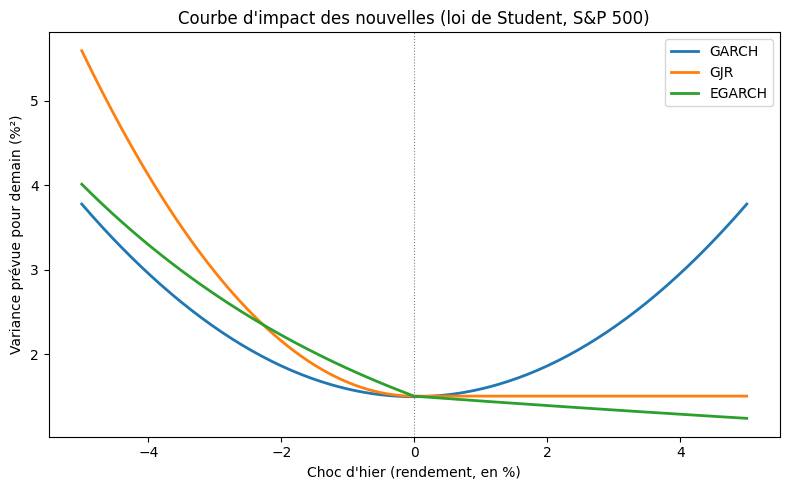

In [ ]:
import matplotlib.pyplot as plt

train_init = spx.loc[:"2014-12-31"]
P = {n: arch_model(train_init["ret"], mean="Constant", dist="t",
                   rescale=False, **SPECS[n]).fit(disp="off") for n in SPECS}

s2bar = train_init["ret"].var()          # niveau "normal" de variance
eps   = np.linspace(-5, 5, 201)          # chocs de -5 % à +5 %

# GARCH : variance demain = omega + alpha*choc² + beta*s2bar
p = P["GARCH"].params
nic_garch = p["omega"] + p["alpha[1]"]*eps**2 + p["beta[1]"]*s2bar

# GJR : même chose, mais les chocs négatifs ont un poids en plus (gamma)
p = P["GJR"].params
nic_gjr = p["omega"] + (p["alpha[1]"] + p["gamma[1]"]*(eps < 0))*eps**2 + p["beta[1]"]*s2bar

# EGARCH : on travaille sur le logarithme de la variance
p = P["EGARCH"].params
z = eps / np.sqrt(s2bar)
nic_egarch = np.exp(p["omega"] + p["alpha[1]"]*(np.abs(z) - np.sqrt(2/np.pi))
                    + p["gamma[1]"]*z + p["beta[1]"]*np.log(s2bar))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(eps, nic_garch,  label="GARCH",  lw=2)
ax.plot(eps, nic_gjr,    label="GJR",    lw=2)
ax.plot(eps, nic_egarch, label="EGARCH", lw=2)
ax.axvline(0, color="grey", lw=0.8, ls=":")
ax.set_xlabel("Choc d'hier (rendement, en %)")
ax.set_ylabel("Variance prévue pour demain (%²)")
ax.set_title("Courbe d'impact des nouvelles (loi de Student, S&P 500)")
ax.legend()
fig.tight_layout()
(root/"figures").mkdir(exist_ok=True)
fig.savefig(root/"figures"/"fig4_news_impact.png", dpi=150)
plt.show()

Courbe d’impact. GARCH est symétrique ; GJR et EGARCH réagissent plus aux baisses (effet de levier). La courbe EGARCH utilise la paramétrisation d’arch (constante √(2/π) pour toute loi).

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

lignes = []
for nom in SPECS:
    r = P[nom]                                # modèles Student estimés sur 2000–2014 (étape 8)
    z = r.std_resid.dropna()                  # résidus standardisés = choc / volatilité prévue
    lb1 = acorr_ljungbox(z,    lags=[10], return_df=True).iloc[0]
    lb2 = acorr_ljungbox(z**2, lags=[10], return_df=True).iloc[0]
    lm  = het_arch(z, nlags=10)
    lignes.append({"modèle": nom,
                   "LB(z) stat": lb1.lb_stat,  "LB(z) p": lb1.lb_pvalue,
                   "LB(z²) stat": lb2.lb_stat, "LB(z²) p": lb2.lb_pvalue,
                   "ARCH-LM stat": lm[0],      "ARCH-LM p": lm[1]})

table_diag = pd.DataFrame(lignes).round(4)
table_diag.to_csv(root/"results"/"table3b_diagnostics.csv", index=False)
display(table_diag)

# pour comparer : le test ARCH-LM sur les rendements bruts (sans modèle)
r_brut = spx.loc[:"2014-12-31", "ret"]
print("ARCH-LM sur les rendements bruts :", [round(x, 4) for x in het_arch(r_brut - r_brut.mean(), nlags=10)[:2]])

,modèle,LB(z) stat,LB(z) p,LB(z²) stat,LB(z²) p,ARCH-LM stat,ARCH-LM p
0,GARCH,22.6325,0.0122,24.4835,0.0064,23.6345,0.0086
1,GJR,20.6436,0.0237,24.4517,0.0065,24.6091,0.0061
2,EGARCH,26.6089,0.0030,28.7939,0.0013,28.4624,0.0015


ARCH-LM sur les rendements bruts : [1007.746, 0.0]


Interprétation. Student gagne toujours en AIC (la loi à queues épaisses ajuste mieux les rendements, ν entre 7,6 et 9,3). Le coefficient α de GJR vaut 0 : c’est la borne de l’optimisation, donc tout l’effet vient de γ (seuls les chocs négatifs font monter la volatilité). Les persistances (0,98 à 0,99) sont inférieures à 1. Hors échantillon, la loi normale fait un peu mieux ou pareil en QLIKE : le meilleur ajustement dans l’échantillon n’est pas la meilleure prévision.